# Topic Modelling of Research Documents
Question 4

In [1]:
import re, string, zipfile, unicodedata
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk import pos_tag
from gensim import corpora
from gensim.models import LdaModel, Phrases
from gensim.models.phrases import Phraser
from gensim.models.coherencemodel import CoherenceModel
# gensim and pyLDAvis print a lot of deprecation warnings, this keeps things tidy
import warnings
warnings.filterwarnings('ignore')
import pyLDAvis
import pyLDAvis.gensim_models

# NLTK data for sentence splitting, stop words, lemmatising and POS tagging
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'averaged_perceptron_tagger_eng']:
    nltk.download(pkg, quiet=True)

### Load and preprocess the corpus (as in Question 3)

In [2]:
# Same loading code as Question 3 - read each .txt straight out of the zip
rows = []
with zipfile.ZipFile('research_corpus.zip') as z:
    for name in sorted(n for n in z.namelist() if n.endswith('.txt')):
        rows.append({'article': name.split('/')[-1].replace('.txt', ''),
                     'content': z.read(name).decode('utf-8', errors='ignore')})

df = pd.DataFrame(rows)

In [3]:
# Same cleaning functions as Question 3, copied in so this notebook runs on its own
# The articles were copied out of PDFs and web pages, so there are lots of junk lines:
# page numbers, running headers, e-mail addresses, figure labels... This catches the ones I found.
NOISE_LINE = re.compile(
    r'^\d+$'                                    # page numbers
    r'|^\d+\s+[A-Z][A-Z\s]+$'                   # running header: 16 EDUCATIONAL RESEARCHER
    r'|^[A-Z]+\s+\d{4}\s+\d+$'                  # running header: OCTOBER 2004 15
    r'|•'                                  # running header: 1100 • RICHEY, KLEIN, NELSON
    r'|^Journal of .* \d+$'                     # running footer: Journal of Social Change 20
    r'|^\d+\s+Qualitative Research'             # running header: 220 Qualitative Research 15(2)
    r'|^[A-Z][a-z]+ \d{3}$'                     # running header: Berger 221
    r'|^(Keywords|Article|Abstract|Corresponding author:?|Full size image)$'
    r'|^(Fig\.|figure)\s*\d+'                   # figure labels
    r'|@'                                       # e-mail addresses
    r'|^[^.]{0,60}University[^.]{0,30}$',       # author affiliations
    re.I)

# Little words that usually stay lowercase even inside a title
SMALL_WORDS = {'a', 'an', 'and', 'as', 'at', 'by', 'for', 'in', 'of', 'on', 'or', 'the', 'to', 'vs', 'with'}

# A line counts as a heading if it's short, doesn't end like a sentence,
# and most of its words start with a capital letter
def is_heading(line):
    words = [w for w in re.findall(r"[A-Za-z][\w'-]*", line) if w.lower() not in SMALL_WORDS]
    return (len(line) < 80 and len(words) <= 10 and not re.search(r'[.,;?!)]$', line)
            and bool(words) and sum(w[0].isupper() for w in words) / len(words) >= 0.75)

# Cleans one whole article: first fix the raw text, then go through it line by line,
# and finally join everything back into normal running text
def denoise_document(text):
    text = unicodedata.normalize('NFKC', text)                                    # unicode normalisation
    text = text.replace('﻿', '').replace('\r', '')                           # byte-order marks, CRLF
    text = re.sub(r'Similar content being viewed by others.*?(?=\nIntroduction)', '', text, flags=re.S)  # web "related articles" block
    text = re.sub(r'Educational Researcher, Vol\. \d+, No\. \d+, pp\. \S+', ' ', text)                 # journal footer inside text
    text = re.sub(r'\nKeywords?:?\s*\n?.*?(?=\n[A-Z][a-z]+\s*\n|\nThe )', '\n', text, flags=re.S)   # keyword lists
    start = text[:200]                                                            # one file had the article pasted twice, so cut at the repeat
    if text.find(start, 200) > 0:
        text = text[:text.find(start, 200)]
    text = re.sub(r'[-]', ' ', text)                                  # private-use bullet symbols
    text = text.translate(str.maketrans({'“': '"', '”': '"', '‘': "'", '’': "'",
                                         '–': '-', '—': '-', '…': '...'}))

    # Now check every line and skip anything that clearly is not article text
    lines = [l.strip() for l in text.split('\n') if l.strip()]
    counts, seen, kept = Counter(lines), set(), []
    for l in lines:
        if NOISE_LINE.search(l):           continue    # headers, footers, page numbers, web leftovers
        if counts[l] >= 3 and len(l) < 60: continue    # other repeated running headers
        if l in seen and len(l) > 30:      continue    # duplicated blocks of text
        if is_heading(l):                  continue    # titles, section headings, author names
        seen.add(l); kept.append(l)

    text = ' '.join(kept)                                         # re-join lines broken by the PDF layout
    text = re.sub(r'(\w)- (\w)', r'\1\2', text)                   # words hyphenated across lines
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)            # URLs
    text = re.sub(r'\([^()]*\d{4}[^()]*\)', ' ', text)            # in-text citations (Author, 2004)
    text = re.sub(r'\(pp?\.\s*\d+[^)]*\)', ' ', text)             # page references (p. 12)
    text = re.sub(r'\b\d+(\.\d+)+\s+(?=[A-Z])', ' ', text)        # section numbers 41.2.1
    text = re.sub(r'(?<=[a-z])\.\d{1,2}(?=\s)', '.', text)        # footnote markers: research.5
    text = re.sub(r'[^\x00-\x7f]', ' ', text)                     # remaining non-ASCII symbols
    text = re.sub(r'\s+([.,;:])', r'\1', text)
    return re.sub(r'\s+', ' ', text).strip()

In [4]:
# NLTK's stop words plus some academic filler words that kept showing up at the top of the counts
stop_words = set(stopwords.words('english')) | {
    'also', 'may', 'one', 'two', 'would', 'could', 'well', 'use', 'used', 'using', 'et', 'al',
    'often', 'however', 'e', 'g', 'eg', 'ie', 'p', 'pp', 'within', 'among', 'example', 'way', 'much'}
lemmatizer = WordNetLemmatizer()

# Converts the POS tag into what WordNet expects, so 'studies' -> 'study' and 'found' -> 'find' work properly
def wordnet_pos(tag):
    return {'J': wordnet.ADJ, 'V': wordnet.VERB, 'R': wordnet.ADV}.get(tag[0], wordnet.NOUN)

# Turns a piece of text into a list of clean, lemmatised words
def preprocess(text):
    text = text.lower()
    text = re.sub(r'\d+', ' ', text)                                                           # numbers
    text = text.translate(str.maketrans(string.punctuation, ' ' * len(string.punctuation)))    # punctuation
    tokens = [w for w in word_tokenize(text) if w.isalpha() and len(w) > 2]                    # tokenise
    tokens = [lemmatizer.lemmatize(w, wordnet_pos(t)) for w, t in pos_tag(tokens)]             # POS-aware lemmatisation
    return [w for w in tokens if w not in stop_words and len(w) > 2]                           # stop words

# Clean the articles and split them into sentences
df['clean_content'] = df['content'].apply(denoise_document)
df['sentences'] = df['clean_content'].apply(sent_tokenize)
df[['article']].assign(sentences=df['sentences'].str.len())

,article,sentences
0,research_1,77
1,research_2,64
2,research_3,160
3,research_4,187
4,research_5,159


### Question 4.1 = LDA topics
LDA is trained on passages of 8 sentences; each article's topic distribution is the average over its passages.

In [5]:
# Five articles are far too few documents for LDA to learn from, so each article is cut
# into chunks of 8 sentences and every chunk is treated as a small document
passages = []
for _, row in df.iterrows():
    sents = row['sentences']
    for i in range(0, len(sents), 8):
        passages.append({'article': row['article'], 'tokens': preprocess(' '.join(sents[i:i + 8]))})
passages = pd.DataFrame(passages)

# Join words that often appear together into one token, e.g. mixed_method, cronbach_alpha
bigram = Phraser(Phrases(passages['tokens'], min_count=5, threshold=10))
passages['tokens'] = passages['tokens'].apply(lambda t: bigram[t])

# Build the vocabulary. filter_extremes drops words found in fewer than 3 passages (too rare)
# and words in more than half of them (too common to tell topics apart)
dictionary = corpora.Dictionary(passages['tokens'])
dictionary.filter_extremes(no_below=3, no_above=0.5)
# Bag-of-words version of each passage, which is the format gensim's LDA wants
corpus = [dictionary.doc2bow(t) for t in passages['tokens']]
print('Passages:', len(corpus), '| Vocabulary:', len(dictionary))

Passages: 82 | Vocabulary: 676


#### Choosing the number of topics (coherence score)

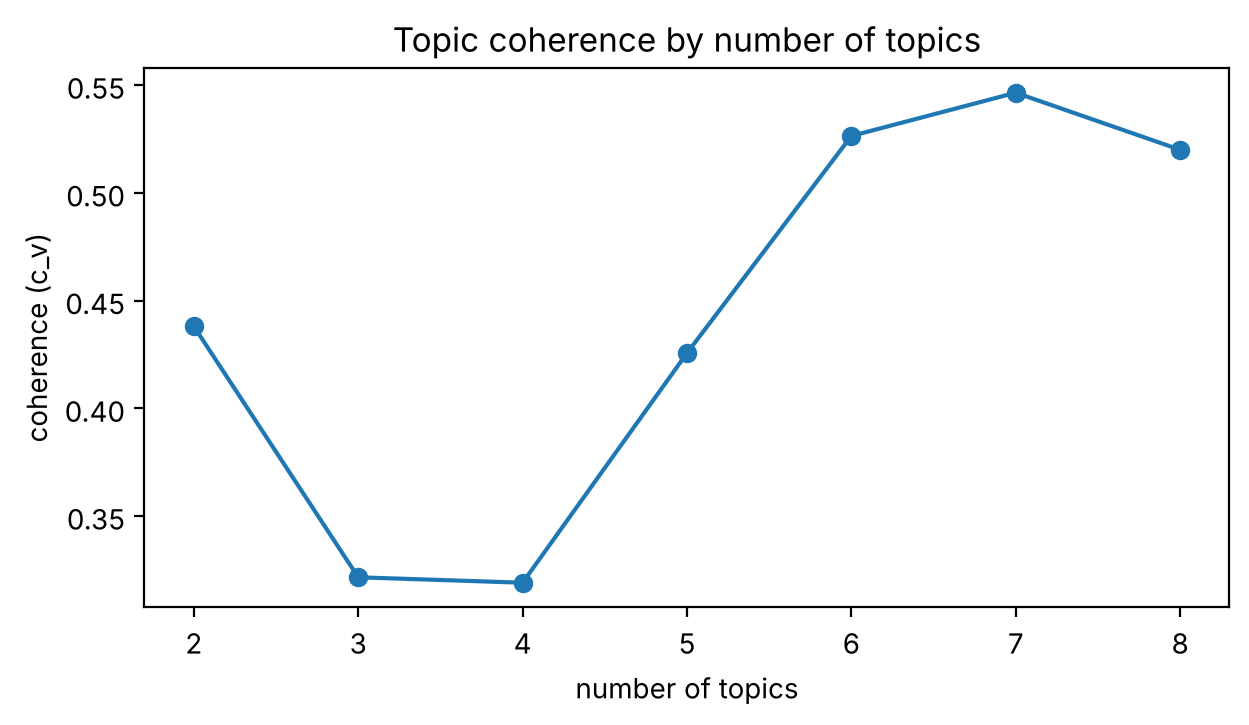

2    0.4380
3    0.3215
4    0.3190
5    0.4256
6    0.5264
7    0.5465
8    0.5200
dtype: float64


In [6]:
# Try 2 to 8 topics and score each one with c_v coherence (higher = the top words of a topic
# actually belong together). random_state is fixed so the results come out the same every run
coherence = {}
for k in range(2, 9):
    model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=k, random_state=42, passes=20, alpha='auto')
    coherence[k] = CoherenceModel(model=model, texts=passages['tokens'], dictionary=dictionary,
                                  coherence='c_v', processes=1).get_coherence()

# Plot the scores to see where it peaks
coherence = pd.Series(coherence)
plt.figure(figsize=(7, 3.5))
plt.plot(coherence.index, coherence.values, marker='o')
plt.xlabel('number of topics'); plt.ylabel('coherence (c_v)'); plt.title('Topic coherence by number of topics')
plt.show()
print(coherence.round(4))

In [7]:
n_topics = int(coherence.idxmax())      # go with whichever number of topics scored best
print('Number of topics:', n_topics)
# Train the final model with that number of topics
lda_model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=n_topics,
                     random_state=42, passes=20, alpha='auto')
print('Coherence (c_v): %.4f' % CoherenceModel(model=lda_model, texts=passages['tokens'], dictionary=dictionary,
                                               coherence='c_v', processes=1).get_coherence())

Number of topics: 7


Coherence (c_v): 0.5465


### Topic word lists

In [8]:
# Top 10 words for each topic, with their probabilities
topic_words = pd.DataFrame({f'Topic {t}': [f'{w} ({p:.3f})' for w, p in lda_model.show_topic(t, topn=10)]
                            for t in range(n_topics)})
topic_words

,Topic 0,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6
0,item (0.028),experience (0.043),data (0.040),mixed_method (0.047),researcher (0.040),development (0.038),instrument (0.028)
1,scale (0.025),researcher (0.032),triangulation (0.033),quantitative (0.039),reflexivity (0.023),process (0.033),cronbach_alpha (0.027)
2,reliability (0.023),participant (0.020),method (0.025),data (0.025),method (0.017),design (0.027),value (0.027)
3,report (0.020),share (0.017),denzin (0.023),researcher (0.019),qualitative_research (0.012),instructional (0.022),report (0.025)
4,student (0.019),make (0.015),multiple (0.018),important (0.015),knowledge (0.011),developmental_research (0.020),science_education (0.020)
5,instrument (0.019),change (0.014),design (0.017),paradigm (0.015),social (0.010),field (0.019),alpha (0.017)
6,knowledge (0.017),woman (0.014),researcher (0.016),qualitative (0.014),personal (0.010),evaluation (0.017),statistic (0.016)
7,cronbach_alpha (0.016),position (0.013),data_triangulation (0.015),qualitative_research (0.013),data (0.010),design_development (0.015),scale (0.016)
8,alpha (0.014),immigrant (0.012),case_study (0.015),question (0.013),self (0.009),model (0.014),reliability (0.016)
9,internal_consistency (0.013),immigration (0.012),methodological_triangulation (0.014),purist (0.012),validity (0.008),product (0.013),author (0.015)


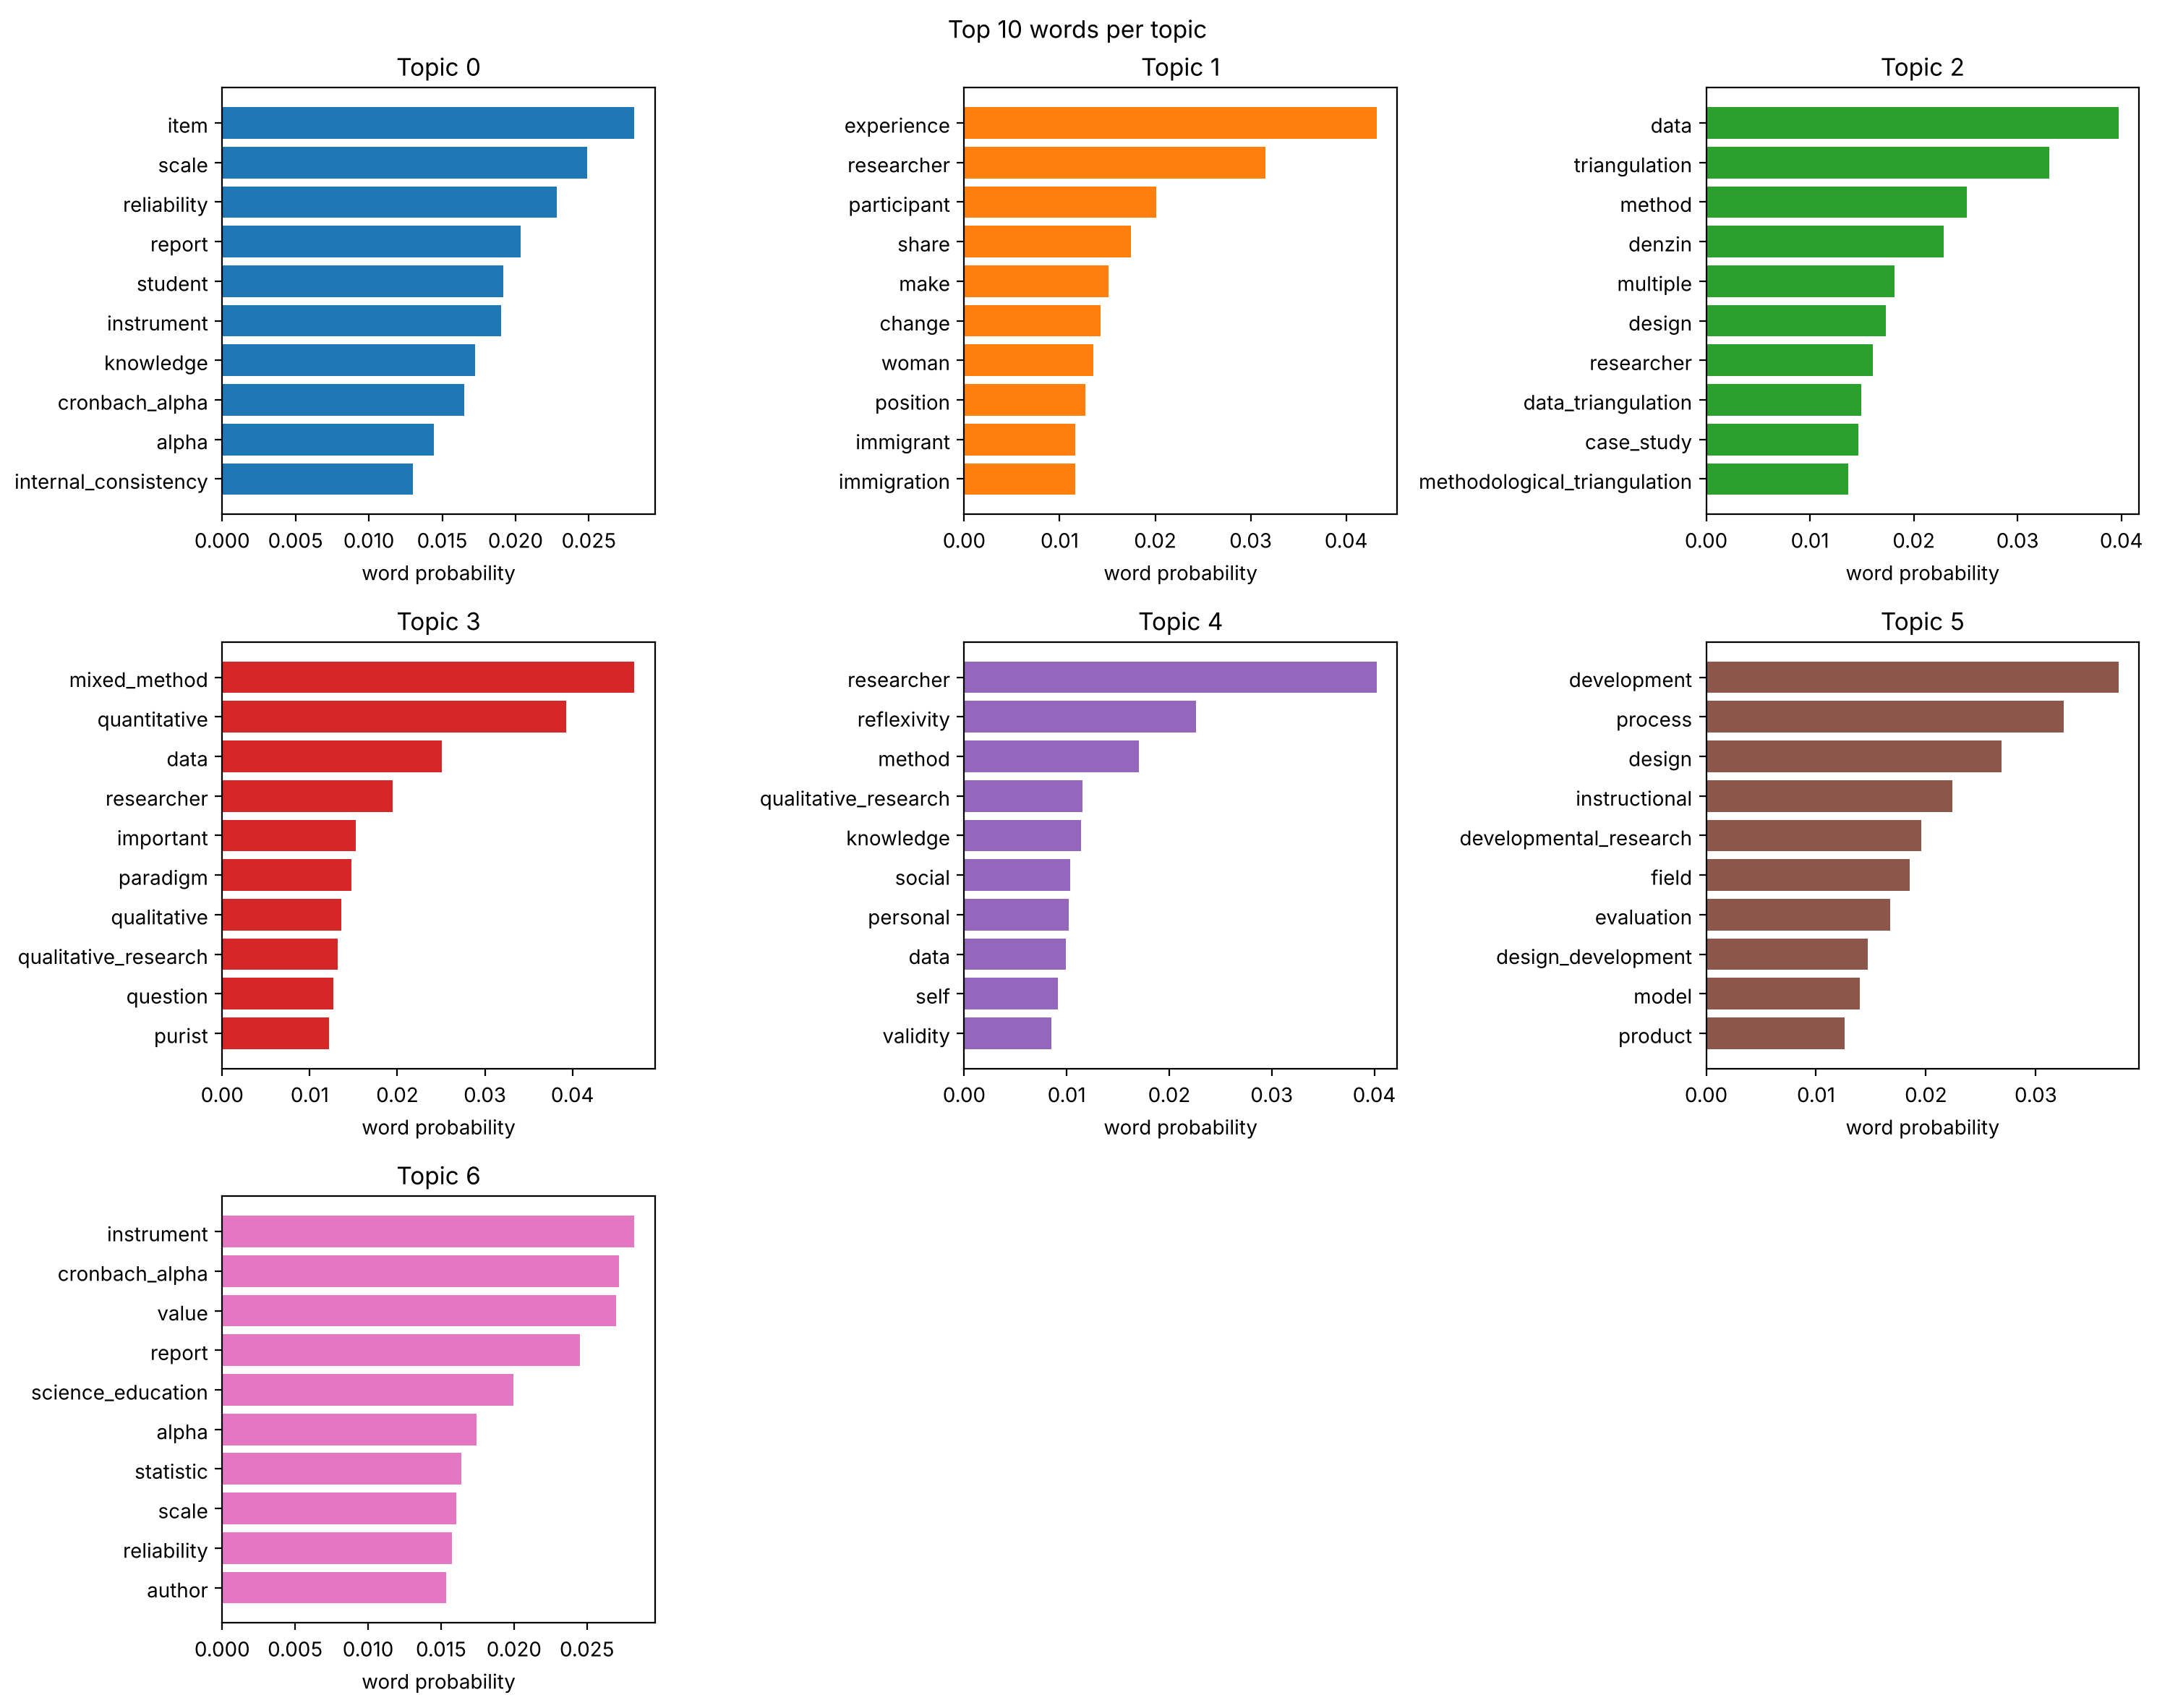

In [9]:
# Same thing as bar charts, one small chart per topic
cols = 3
rows = int(np.ceil(n_topics / cols))
fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
for t, ax in enumerate(axes.ravel()):
    if t >= n_topics:          # hide the leftover empty plots in the grid
        ax.axis('off'); continue
    words, probs = zip(*lda_model.show_topic(t, topn=10))
    ax.barh(words[::-1], probs[::-1], color=sns.color_palette('tab10')[t])
    ax.set_title(f'Topic {t}'); ax.set_xlabel('word probability')
plt.suptitle('Top 10 words per topic'); plt.tight_layout(); plt.show()

### Topic distribution

In [10]:
# Topic mix of every passage (minimum_probability=0 so no topic is left out)
doc_topics = np.zeros((len(corpus), n_topics))
for i, bow in enumerate(corpus):
    for t, p in lda_model.get_document_topics(bow, minimum_probability=0):
        doc_topics[i, t] = p

# Average the passages back up to article level, then pick each article's main topic
passage_topics = pd.DataFrame(doc_topics, columns=[f'Topic {t}' for t in range(n_topics)])
passage_topics['article'] = passages['article']
article_topics = passage_topics.groupby('article').mean()
article_topics['dominant topic'] = article_topics.idxmax(axis=1)
article_topics.round(3)

,Topic 0,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6,dominant topic
article,,,,,,,,
research_1,0.000,0.000,0.112,0.441,0.386,0.039,0.022,Topic 3
research_2,0.010,0.501,0.001,0.019,0.455,0.001,0.015,Topic 1
research_3,0.010,0.009,0.028,0.003,0.067,0.883,0.001,Topic 5
research_4,0.331,0.020,0.021,0.013,0.001,0.016,0.599,Topic 6
research_5,0.000,0.057,0.479,0.159,0.237,0.043,0.024,Topic 2


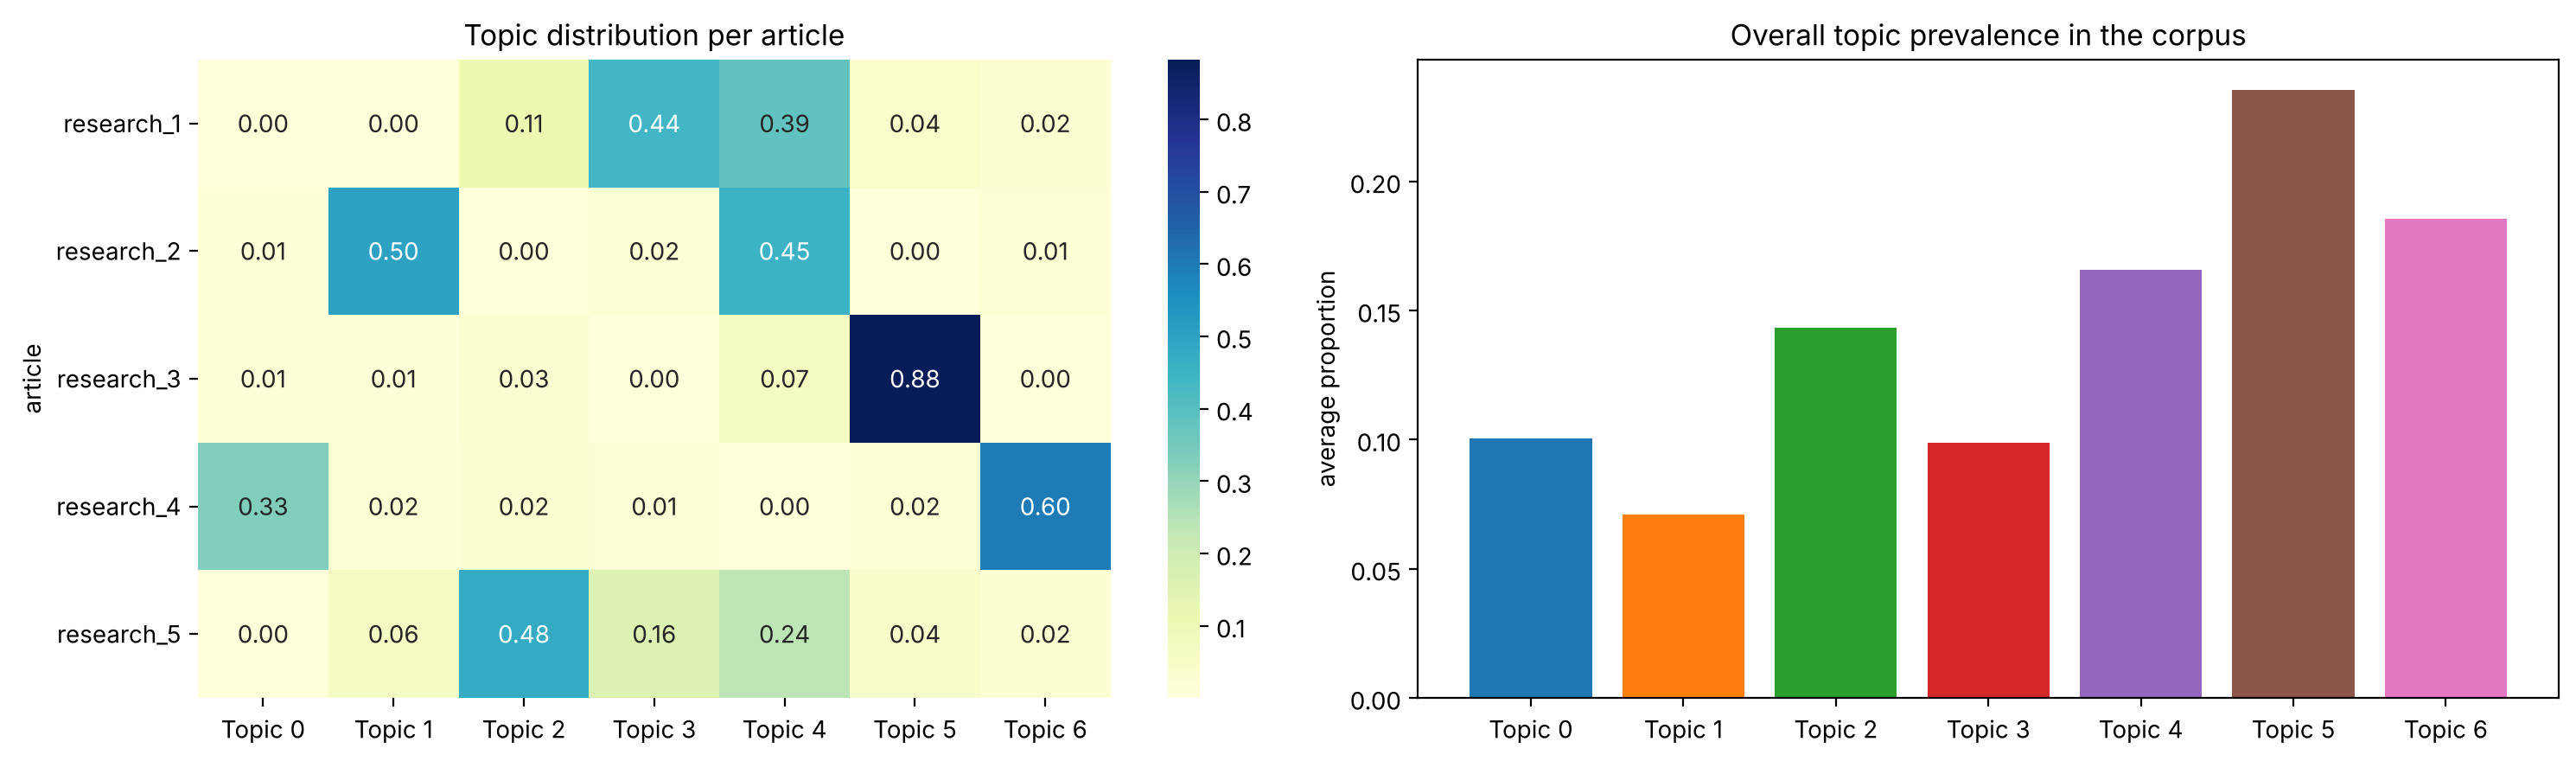

In [11]:
# Left: how much of each topic is in each article. Right: how common each topic is overall
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(article_topics.drop(columns='dominant topic'), annot=True, fmt='.2f', cmap='YlGnBu', ax=axes[0])
axes[0].set_title('Topic distribution per article')

prevalence = passage_topics.drop(columns='article').mean()
axes[1].bar(prevalence.index, prevalence.values, color=sns.color_palette('tab10')[:n_topics])
axes[1].set_title('Overall topic prevalence in the corpus'); axes[1].set_ylabel('average proportion')
plt.tight_layout(); plt.show()

**Comment:** 7 topics give the highest coherence (c_v = 0.547). The topics are: 0 = measurement scales and reliability, 1 = researcher's shared experience, 2 = triangulation, 3 = mixed methods paradigm, 4 = reflexivity in qualitative research, 5 = developmental research / instructional design, 6 = Cronbach's alpha. Each article has one dominant topic.

### Question 4.2 = Intertopic Distance Map (pyLDAvis)
Each circle is a topic: its size is the topic's prevalence and the distance between circles shows how different the topics are. Select a topic to see its most salient/relevant words; the λ slider adjusts relevance.

In [12]:
# Interactive intertopic distance map. It's also saved as an HTML file so it can be opened
# in a browser without re-running the notebook
pyLDAvis.enable_notebook()
# sort_topics=False keeps the same topic order as gensim (pyLDAvis just counts from 1 instead of 0)
vis = pyLDAvis.gensim_models.prepare(lda_model, corpus, dictionary, mds='mmds', sort_topics=False)
pyLDAvis.save_html(vis, 'lda_intertopic_map.html')
vis

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.146822  0.194075       1        1  12.054308
1      0.026889 -0.218942       2        1   6.604353
2     -0.211009 -0.122023       3        1  13.610576
3     -0.186982  0.045808       4        1   9.084873
4     -0.037461 -0.077076       5        1  17.877748
5      0.243818 -0.085812       6        1  20.146701
6      0.017924  0.263969       7        1  20.621442, topic_info=             Term       Freq      Total Category  logprob  loglift
117    researcher  88.000000  88.000000  Default  30.0000  30.0000
34   mixed_method  33.000000  33.000000  Default  29.0000  29.0000
77           data  67.000000  67.000000  Default  28.0000  28.0000
216    experience  29.000000  29.000000  Default  27.0000  27.0000
56   quantitative  29.000000  29.000000  Default  26.0000  26.0000
..            ...        ...        ...      ...      ...      ...
443      consider  10.495781  25.623666   Topic7  -4.8589   0.6863
212     different  11.268520  32.077117   Topic7  -4.7879   0.5327
48        present   9.027363  20.066089   Topic7  -5.0096   0.7801
102       include   9.474857  34.597355   Topic7  -4.9613   0.2837
124       student   9.455005  39.248495   Topic7  -4.9634   0.1555

[400 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
576       1  0.363803  acceptable
576       7  0.606339  acceptable
464       1  0.459848     achieve
464       2  0.459848     achieve
655       1  0.887765        acid
...     ...       ...         ...
439       2  0.584266   worldview
439       4  0.292133   worldview
463       1  0.145189        year
463       5  0.145189        year
463       7  0.653349        year

[851 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5, 6, 7])

Most salient words per topic (λ = 0.6):

In [13]:
# Same relevance score the λ slider uses: λ=1 ranks words by how likely they are in the topic,
# lower values favour words that are specific to that topic. 0.6 is what Sievert & Shirley recommend
info = vis.topic_info
lam = 0.6
info['relevance'] = lam * info['logprob'] + (1 - lam) * info['loglift']
salient = {}
for cat in sorted(c for c in info['Category'].unique() if c != 'Default'):
    terms = info[info['Category'] == cat].nlargest(10, 'relevance')['Term'].tolist()
    # pyLDAvis numbers topics from 1, so subtract 1 to match the gensim numbering
    salient[f'Topic {int(cat.replace("Topic", "")) - 1}'] = terms
pd.DataFrame(salient)

,Topic 0,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6
0,item,experience,triangulation,mixed_method,researcher,development,cronbach_alpha
1,scale,share,data,quantitative,reflexivity,process,instrument
2,reliability,woman,denzin,paradigm,method,instructional,value
3,student,participant,method,data,personal,developmental_research,science_education
4,solution,immigrant,multiple,important,social,design,report
5,internal_consistency,immigration,data_triangulation,purist,qualitative_research,field,statistic
6,report,change,methodological_triangulation,difference,self,evaluation,alpha
7,tier,researcher,case_study,question,source,design_development,high
8,factor,reading,reality,qualitative,position,model,author
9,coefficient,mean,design,qualitative_research,validity,product,test
